# AtliQ Hospitality – Business Performance Analysis Using Python

## Project Overview

This project analyses the business performance of AtliQ Hospitality
across four major Indian cities using Python.

The analysis focuses on hotel booking data from May to July 2022
to evaluate occupancy, revenue performance, booking platform
contribution and cancellation patterns.

The objective is to identify business opportunities, understand
performance gaps and provide data-driven recommendations to
support management decision-making.

## Business Objectives

- Evaluate hotel occupancy across room classes and cities.
- Compare weekday and weekend occupancy.
- Identify major revenue-generating markets.
- Analyse monthly revenue trends.
- Evaluate booking platform revenue contribution.
- Identify cancellation patterns across booking channels.
- Estimate potential unrealized revenue associated with
  cancellations and no-shows.
- Provide actionable business recommendations.

## Tools Used
Python, pandas, Matplotlib and Jupyter Notebook.

## Data Source
Codebasics Data Analytics Bootcamp hospitality dataset. This project builds on the guided course exercise.

## 1. Import Libraries and Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_bookings = pd.read_csv("datasets/fact_bookings.csv")
df_agg_bookings = pd.read_csv("datasets/fact_aggregated_bookings.csv")
df_hotels = pd.read_csv("datasets/dim_hotels.csv")
df_rooms = pd.read_csv("datasets/dim_rooms.csv")
df_date = pd.read_csv("datasets/dim_date.csv")

In [3]:
df_bookings.head(4)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640


## 2. Explore the Data

In [4]:
df_bookings.shape

(134590, 12)

In [5]:
df_bookings.info()

<class 'pandas.DataFrame'>
RangeIndex: 134590 entries, 0 to 134589
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   booking_id         134590 non-null  str    
 1   property_id        134590 non-null  int64  
 2   booking_date       134590 non-null  str    
 3   check_in_date      134590 non-null  str    
 4   checkout_date      134590 non-null  str    
 5   no_guests          134587 non-null  float64
 6   room_category      134590 non-null  str    
 7   booking_platform   134590 non-null  str    
 8   ratings_given      56683 non-null   float64
 9   booking_status     134590 non-null  str    
 10  revenue_generated  134590 non-null  int64  
 11  revenue_realized   134590 non-null  int64  
dtypes: float64(2), int64(3), str(7)
memory usage: 12.3 MB


In [6]:
df_bookings.isna().sum()

booking_id               0
property_id              0
booking_date             0
check_in_date            0
checkout_date            0
no_guests                3
room_category            0
booking_platform         0
ratings_given        77907
booking_status           0
revenue_generated        0
revenue_realized         0
dtype: int64

In [7]:
df_bookings["booking_id"].duplicated().sum()

np.int64(0)

In [8]:
df_bookings.booking_platform.unique()

<StringArray>
[ 'direct online',         'others',        'logtrip',       'tripster',
   'makeyourtrip',        'journey', 'direct offline']
Length: 7, dtype: str

In [9]:
df_bookings.describe()

,property_id,no_guests,ratings_given,revenue_generated,revenue_realized
count,134590.000000,134587.000000,56683.000000,1.345900e+05,134590.000000
mean,18061.113493,2.036170,3.619004,1.537805e+04,12696.123256
std,1093.055847,1.034885,1.235009,9.303604e+04,6928.108124
min,16558.000000,-17.000000,1.000000,6.500000e+03,2600.000000
25%,17558.000000,1.000000,3.000000,9.900000e+03,7600.000000
50%,17564.000000,2.000000,4.000000,1.350000e+04,11700.000000
75%,18563.000000,2.000000,5.000000,1.800000e+04,15300.000000
max,19563.000000,6.000000,5.000000,2.856000e+07,45220.000000


<Axes: ylabel='booking_platform'>

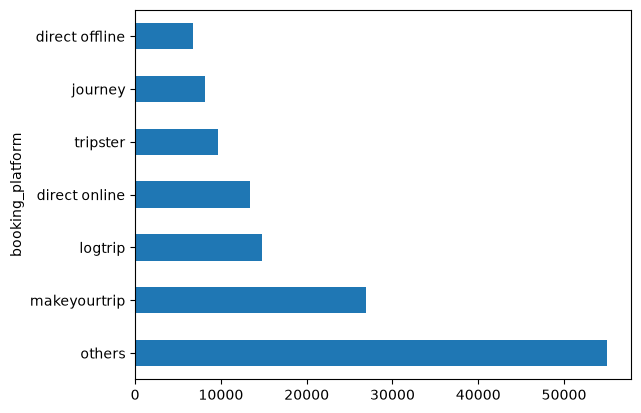

In [10]:
df_bookings.booking_platform.value_counts().plot(kind="barh")

In [11]:
df_hotels.city.value_counts().sort_values()

city
Delhi        5
Hyderabad    6
Bangalore    6
Mumbai       8
Name: count, dtype: int64

## 3. Data Cleaning and Validation

### 3.1 Check Invalid Guest Counts

In [12]:
df_bookings[df_bookings["no_guests"] <= 0].head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640
17924,May122218559RT44,18559,12/5/2022,12/5/2022,14-05-22,-10.0,RT4,direct online,NaN,No Show,20900,20900
18020,May122218561RT22,18561,8/5/2022,12/5/2022,14-05-22,-12.0,RT2,makeyourtrip,NaN,Cancelled,9000,3600
18119,May122218562RT311,18562,5/5/2022,12/5/2022,17-05-22,-6.0,RT3,direct offline,5.0,Checked Out,16800,16800


In [13]:
(df_bookings["no_guests"] <= 0).sum()

np.int64(9)

In [14]:
# Keep booking and revenue records; mark invalid guest counts as missing.
df_bookings.loc[df_bookings["no_guests"] <= 0, "no_guests"] = float("nan")

In [15]:
(df_bookings["no_guests"] <= 0).sum()

np.int64(0)

### 3.2 Investigate Revenue Outliers

In [16]:
df_bookings["revenue_generated"].describe()

count    1.345900e+05
mean     1.537805e+04
std      9.303604e+04
min      6.500000e+03
25%      9.900000e+03
50%      1.350000e+04
75%      1.800000e+04
max      2.856000e+07
Name: revenue_generated, dtype: float64

In [17]:
avg,std = df_bookings.revenue_generated.mean(),df_bookings.revenue_generated.std()

In [18]:
higher_limit = avg + 3*std
higher_limit

np.float64(294486.17014021333)

In [19]:
lower_limit = avg - 3*std
lower_limit

np.float64(-263730.06188551383)

In [20]:
# Inspect unusual revenue values instead of deleting valid bookings.
df_bookings[df_bookings.revenue_generated > higher_limit]

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100
111,May012216559RT32,16559,29-04-22,1/5/2022,2/5/2022,6.0,RT3,direct online,NaN,Checked Out,28560000,28560
315,May012216562RT22,16562,28-04-22,1/5/2022,4/5/2022,2.0,RT2,direct offline,3.0,Checked Out,12600000,12600
562,May012217559RT118,17559,26-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,2000000,4420
129176,Jul282216562RT26,16562,21-07-22,28-07-22,29-07-22,2.0,RT2,direct online,3.0,Checked Out,10000000,12600


In [21]:
df_bookings.revenue_realized.describe()

count    134590.000000
mean      12696.123256
std        6928.108124
min        2600.000000
25%        7600.000000
50%       11700.000000
75%       15300.000000
max       45220.000000
Name: revenue_realized, dtype: float64

In [22]:
higher_limit = df_bookings.revenue_realized.mean() + 3*df_bookings.revenue_realized.std()
higher_limit

np.float64(33480.44762788103)

In [23]:
df_bookings[df_bookings.revenue_realized>higher_limit]

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
137,May012216559RT41,16559,27-04-22,1/5/2022,7/5/2022,4.0,RT4,others,NaN,Checked Out,38760,38760
139,May012216559RT43,16559,1/5/2022,1/5/2022,2/5/2022,6.0,RT4,tripster,3.0,Checked Out,45220,45220
143,May012216559RT47,16559,28-04-22,1/5/2022,3/5/2022,3.0,RT4,others,5.0,Checked Out,35530,35530
149,May012216559RT413,16559,24-04-22,1/5/2022,7/5/2022,5.0,RT4,logtrip,NaN,Checked Out,41990,41990
222,May012216560RT45,16560,30-04-22,1/5/2022,3/5/2022,5.0,RT4,others,3.0,Checked Out,34580,34580
...,...,...,...,...,...,...,...,...,...,...,...,...
134331,Jul312219560RT412,19560,31-07-22,31-07-22,1/8/2022,6.0,RT4,others,2.0,Checked Out,39900,39900
134467,Jul312219562RT45,19562,28-07-22,31-07-22,1/8/2022,6.0,RT4,makeyourtrip,4.0,Checked Out,39900,39900
134474,Jul312219562RT412,19562,25-07-22,31-07-22,6/8/2022,5.0,RT4,direct offline,5.0,Checked Out,37050,37050
134581,Jul312217564RT42,17564,31-07-22,31-07-22,1/8/2022,4.0,RT4,makeyourtrip,4.0,Checked Out,38760,38760


In [24]:
df_bookings[df_bookings.room_category=="RT4"].revenue_realized.describe()

count    16073.000000
mean     23440.103652
std       9048.865206
min       7600.000000
25%      19000.000000
50%      26600.000000
75%      32300.000000
max      45220.000000
Name: revenue_realized, dtype: float64

In [25]:
df_bookings[df_bookings.room_category == "RT4"].revenue_realized.mean() + 3 * df_bookings[df_bookings.room_category == "RT4"].revenue_realized.std()

np.float64(50586.69926930781)

### 3.3 Check Missing Values

In [26]:
df_bookings.isnull().sum()

booking_id               0
property_id              0
booking_date             0
check_in_date            0
checkout_date            0
no_guests               12
room_category            0
booking_platform         0
ratings_given        77907
booking_status           0
revenue_generated        0
revenue_realized         0
dtype: int64

## 4. Calculate Occupancy Percentage

**Metric Definition:**

Occupancy Rate (%) = (Successful Bookings / Available Capacity) × 100

For aggregated analysis, occupancy is calculated using total
successful bookings divided by total available capacity.

This ensures that properties with different room capacities
are appropriately represented in the analysis.

In [27]:
df_agg_bookings.isna().sum()

property_id            0
check_in_date          0
room_category          0
successful_bookings    0
capacity               2
dtype: int64

In [28]:
# Exclude invalid capacity records from occupancy analysis only.
df_agg_bookings = df_agg_bookings[df_agg_bookings["capacity"] > 0].copy()
df_agg_bookings[df_agg_bookings["successful_bookings"] > df_agg_bookings["capacity"]]

,property_id,check_in_date,room_category,successful_bookings,capacity
3,17558,1-May-22,RT1,30,19.0
12,16563,1-May-22,RT1,100,41.0
4136,19558,11-Jun-22,RT2,50,39.0
6209,19560,2-Jul-22,RT1,123,26.0
8522,19559,25-Jul-22,RT1,35,24.0
9194,18563,31-Jul-22,RT4,20,18.0


In [29]:
# Exclude records where bookings exceed capacity.
df_agg_bookings = df_agg_bookings[df_agg_bookings["successful_bookings"] <= df_agg_bookings["capacity"]].copy()

In [30]:
df_agg_bookings['occ_pct'] = (
    df_agg_bookings['successful_bookings']
    / df_agg_bookings['capacity']
    * 100
).round(2)

df_agg_bookings.head(4)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct
0,16559,1-May-22,RT1,25,30.0,83.33
1,19562,1-May-22,RT1,28,30.0,93.33
2,19563,1-May-22,RT1,23,30.0,76.67
4,16558,1-May-22,RT1,18,19.0,94.74


## 5. Explore Occupancy by Room Category

In [31]:
category_occupancy = df_agg_bookings.groupby("room_category")[["successful_bookings", "capacity"]].sum()
category_occupancy["occ_pct"] = (category_occupancy["successful_bookings"] / category_occupancy["capacity"] * 100).round(2)
category_occupancy["occ_pct"].sort_values(ascending=False)

room_category
RT4    59.22
RT1    57.84
RT2    57.61
RT3    57.58
Name: occ_pct, dtype: float64

## 6. Analyse Occupancy by Room Class

In [32]:
df_rooms

,room_id,room_class
0,RT1,Standard
1,RT2,Elite
2,RT3,Premium
3,RT4,Presidential


In [33]:
df_rooms_all =pd.merge(df_agg_bookings,df_rooms,left_on ="room_category",right_on ="room_id", validate="many_to_one")
df_rooms_all.head(4)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_id,room_class
0,16559,1-May-22,RT1,25,30.0,83.33,RT1,Standard
1,19562,1-May-22,RT1,28,30.0,93.33,RT1,Standard
2,19563,1-May-22,RT1,23,30.0,76.67,RT1,Standard
3,16558,1-May-22,RT1,18,19.0,94.74,RT1,Standard


In [34]:
room_occupancy = df_rooms_all.groupby("room_class")[["successful_bookings", "capacity"]].sum()
room_occupancy["occ_pct"] = (room_occupancy["successful_bookings"] / room_occupancy["capacity"] * 100).round(2)
room_occupancy["occ_pct"].sort_values(ascending=False)

room_class
Presidential    59.22
Standard        57.84
Elite           57.61
Premium         57.58
Name: occ_pct, dtype: float64

### Key Findings

- Presidential rooms recorded the highest occupancy at 59.22%.
- Premium rooms recorded the lowest occupancy at 57.58%.
- Occupancy is relatively consistent across all room classes,
  with a difference of only 1.64 percentage points.

### Business Recommendation

Evaluate room pricing, revenue and profitability alongside
occupancy before making changes to room inventory.

## 7. Analyse Occupancy by City

In [35]:
df_hotels.head(4)

,property_id,property_name,category,city
0,16558,Atliq Grands,Luxury,Delhi
1,16559,Atliq Exotica,Luxury,Mumbai
2,16560,Atliq City,Business,Delhi
3,16561,Atliq Blu,Luxury,Delhi


In [36]:
df_hotels_all = pd.merge(df_rooms_all, df_hotels, on="property_id", validate="many_to_one")
df_hotels_all.head(4)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_id,room_class,property_name,category,city
0,16559,1-May-22,RT1,25,30.0,83.33,RT1,Standard,Atliq Exotica,Luxury,Mumbai
1,19562,1-May-22,RT1,28,30.0,93.33,RT1,Standard,Atliq Bay,Luxury,Bangalore
2,19563,1-May-22,RT1,23,30.0,76.67,RT1,Standard,Atliq Palace,Business,Bangalore
3,16558,1-May-22,RT1,18,19.0,94.74,RT1,Standard,Atliq Grands,Luxury,Delhi


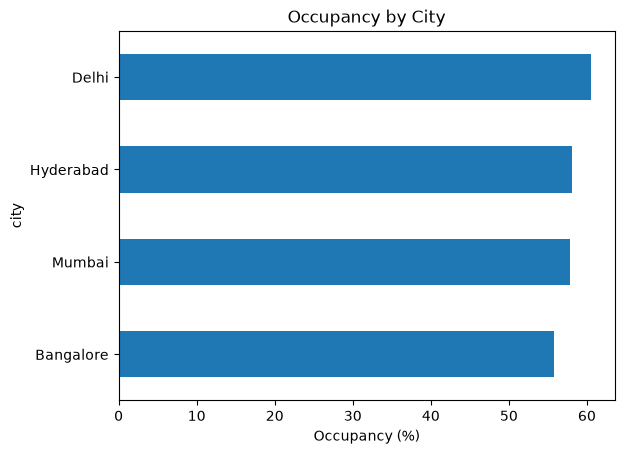

In [37]:
city_occupancy = df_hotels_all.groupby("city")[["successful_bookings", "capacity"]].sum()
city_occupancy["occ_pct"] = (city_occupancy["successful_bookings"] / city_occupancy["capacity"] * 100).round(2)
city_occupancy["occ_pct"].sort_values().plot(kind="barh", title="Occupancy by City")
plt.xlabel("Occupancy (%)")
plt.show()

### Key Findings

- Delhi recorded the highest occupancy at 60.52%.
- Hyderabad and Mumbai recorded occupancy rates of
  58.07% and 57.87%, respectively.
- Bangalore recorded the lowest occupancy at 55.76%.

### Business Recommendation

Investigate pricing, customer demand and local competition
in Bangalore to identify opportunities to improve occupancy.

## 8. Compare Weekday and Weekend Occupancy

In [38]:
df_date.head(4)

,date,mmm yy,week no,day_type
0,01-May-22,May 22,W 19,weekend
1,02-May-22,May 22,W 19,weekeday
2,03-May-22,May 22,W 19,weekeday
3,04-May-22,May 22,W 19,weekeday


In [39]:
df_date["day_type"] = df_date["day_type"].replace("weekeday", "weekday")

df_date["date"] = pd.to_datetime(df_date["date"], format="%d-%b-%y")
df_hotels_all["check_in_date"] = pd.to_datetime(df_hotels_all["check_in_date"], format="%d-%b-%y")
df = pd.merge(df_hotels_all, df_date, left_on="check_in_date", right_on="date", how="left", validate="many_to_one")
assert df["day_type"].notna().all()

In [40]:

day_occupancy = df.groupby("day_type")[
    ["successful_bookings", "capacity"]
].sum()

day_occupancy["occ_pct"] = (
    day_occupancy["successful_bookings"] /
    day_occupancy["capacity"] * 100
).round(2)

day_occupancy

,successful_bookings,capacity,occ_pct
day_type,,,
weekday,84354,164296.0,51.34
weekend,50087,68067.0,73.58


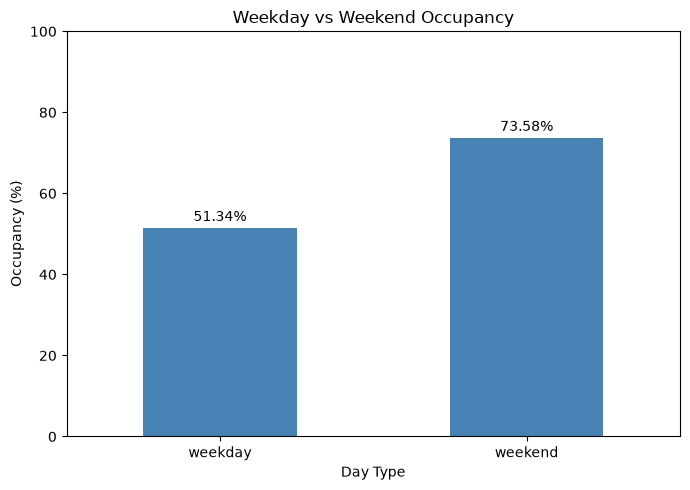

In [41]:
ax = day_occupancy["occ_pct"].plot(
    kind="bar",
    figsize=(7, 5),
    color="steelblue",
    rot=0,
    width=0.5
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Weekday vs Weekend Occupancy")
plt.xlabel("Day Type")
plt.ylabel("Occupancy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Key Findings
- Weekend occupancy is 73.58%, compared with 51.34% on weekdays.
- The gap is 22.24 percentage points.

### Business Recommendation
Test weekday corporate packages and promotions, monitoring both occupancy and realized revenue.

## 9. Compare City Occupancy in June 2022

**Business Objective:** To compare occupancy across cities in June 2022
and identify markets with stronger and weaker room utilization.

In [42]:
df_june_22 = df[df["mmm yy"]=="Jun 22"]
df_june_22.head(3)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_id,room_class,property_name,category,city,date,mmm yy,week no,day_type
3096,16559,2022-06-01,RT1,14,30.0,46.67,RT1,Standard,Atliq Exotica,Luxury,Mumbai,2022-06-01,Jun 22,W 23,weekday
3097,18560,2022-06-01,RT1,18,30.0,60.00,RT1,Standard,Atliq City,Business,Hyderabad,2022-06-01,Jun 22,W 23,weekday
3098,19562,2022-06-01,RT1,18,30.0,60.00,RT1,Standard,Atliq Bay,Luxury,Bangalore,2022-06-01,Jun 22,W 23,weekday


In [43]:
june_occupancy = df_june_22.groupby("city")[["successful_bookings", "capacity"]].sum()
june_occupancy["occ_pct"] = (june_occupancy["successful_bookings"] / june_occupancy["capacity"] * 100).round(2)
june_occupancy["occ_pct"].sort_values(ascending=False)

city
Delhi        60.48
Mumbai       57.68
Hyderabad    57.67
Bangalore    55.42
Name: occ_pct, dtype: float64

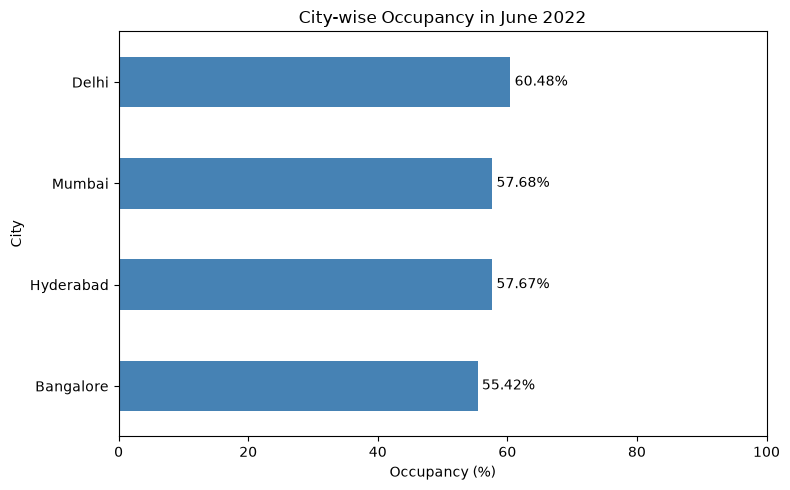

In [44]:
ax = june_occupancy["occ_pct"].sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("City-wise Occupancy in June 2022")
plt.xlabel("Occupancy (%)")
plt.ylabel("City")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Key Findings

- Delhi recorded the highest occupancy at 60.48%.
- Mumbai and Hyderabad recorded nearly identical occupancy rates.
- Bangalore recorded the lowest occupancy at 55.42%.
- The difference between the highest and lowest occupancy
  rates is 5.06 percentage points.

### Business Impact

Bangalore has relatively lower room utilization compared to
other cities, indicating an opportunity to improve occupancy.

### Business Recommendation

Management should investigate pricing, customer demand and
local competition in Bangalore and consider targeted
promotional campaigns to improve room utilization.

## 10. Explore August Sample Records

**Objective:** To examine newly available August records and
check their consistency with the existing dataset.

In [45]:
df_august = pd.read_csv("datasets/new_data_august.csv")
df_august.head(4)

,property_id,property_name,category,city,room_category,room_class,check_in_date,mmm yy,week no,day_type,successful_bookings,capacity,occ%
0,16559,Atliq Exotica,Luxury,Mumbai,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,30,30,100.00
1,19562,Atliq Bay,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,21,30,70.00
2,19563,Atliq Palace,Business,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,23,30,76.67
3,19558,Atliq Grands,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,30,40,75.00


In [46]:
df_august.columns


Index(['property_id', 'property_name', 'category', 'city', 'room_category',
       'room_class', 'check_in_date', 'mmm yy', 'week no', 'day_type',
       'successful_bookings', 'capacity', 'occ%'],
      dtype='str')

In [47]:
df.columns

Index(['property_id', 'check_in_date', 'room_category', 'successful_bookings',
       'capacity', 'occ_pct', 'room_id', 'room_class', 'property_name',
       'category', 'city', 'date', 'mmm yy', 'week no', 'day_type'],
      dtype='str')

In [48]:
df_august.shape

(7, 13)

In [49]:
df.shape

(9192, 15)

In [50]:
df_august = df_august.rename(columns={"occ%": "occ_pct"})
df_august["day_type"] = df_august["day_type"].replace("weekeday", "weekday")
df_august.head()

,property_id,property_name,category,city,room_category,room_class,check_in_date,mmm yy,week no,day_type,successful_bookings,capacity,occ_pct
0,16559,Atliq Exotica,Luxury,Mumbai,RT1,Standard,01-Aug-22,Aug-22,W 32,weekday,30,30,100.00
1,19562,Atliq Bay,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekday,21,30,70.00
2,19563,Atliq Palace,Business,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekday,23,30,76.67
3,19558,Atliq Grands,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekday,30,40,75.00
4,19560,Atliq City,Business,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekday,20,26,76.92


In [51]:
df_august.shape

(7, 13)

### Data Quality Observations

- The August dataset contains only seven records.
- The occupancy column has been renamed to maintain consistency
  with the main dataset.
- August records are kept separate because they do not represent
  a complete month of hotel operations.
- Including these incomplete records in monthly performance
  comparisons could lead to misleading conclusions.

## 11. Analyse Realized Revenue by City

**Business Objective:** To identify the major revenue-generating
cities and understand the geographical distribution of revenue.

In [52]:
df_bookings_all = pd.merge(df_bookings, df_hotels, on="property_id", how="left", validate="many_to_one")
assert df_bookings_all["city"].notna().all()
assert df_bookings_all["booking_id"].is_unique
assert len(df_bookings_all) == len(df_bookings)
df_bookings_all.head(4)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,NaN,RT1,direct online,1.0,Checked Out,10010,10010,Atliq Grands,Luxury,Delhi
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100,Atliq Grands,Luxury,Delhi
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,NaN,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi


In [53]:
city_revenue = df_bookings_all.groupby(
    "city"
)["revenue_realized"].sum()

city_revenue.sort_values(ascending=False)

city
Mumbai       668640991
Bangalore    420397050
Hyderabad    325232870
Delhi        294500318
Name: revenue_realized, dtype: int64

In [54]:
city_revenue_pct = (
    city_revenue / city_revenue.sum() * 100
).round(2)

city_revenue_pct.sort_values(ascending=False)

city
Mumbai       39.13
Bangalore    24.60
Hyderabad    19.03
Delhi        17.23
Name: revenue_realized, dtype: float64

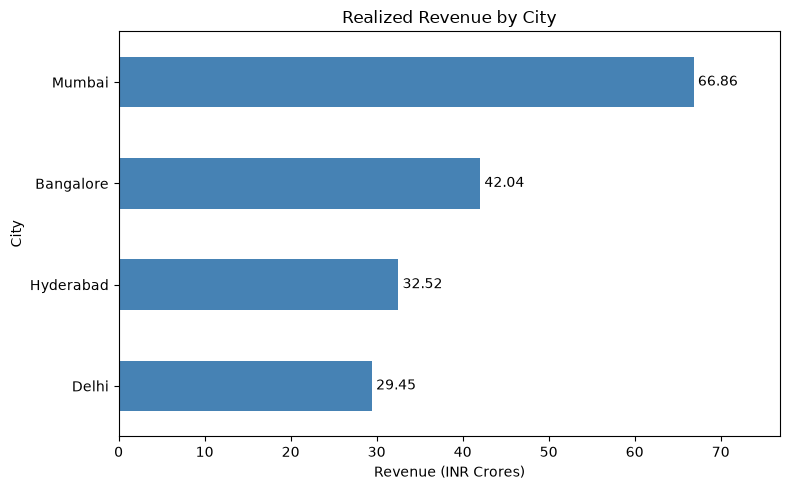

In [55]:
ax = (city_revenue / 10000000).sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title("Realized Revenue by City")
plt.xlabel("Revenue (INR Crores)")
plt.ylabel("City")
plt.margins(x=0.15)
plt.tight_layout()
plt.show()

### Key Findings
- Mumbai leads with ₹66.86 crore (39.1% of total).
- Bangalore contributes ₹42.04 crore. Delhi has the lowest revenue at ₹29.45 crore.

### Business Recommendation
Maintain strong markets and investigate capacity, pricing and demand before judging lower-revenue cities.

## 12. Analyse Monthly Realized Revenue

**Business Objective:** To identify monthly revenue trends
and evaluate changes in financial performance over time.

In [56]:
df_bookings_all["check_in_date"] = pd.to_datetime(df_bookings_all["check_in_date"], format="mixed", dayfirst=True)
df_bookings_all["month_year"] = df_bookings_all["check_in_date"].dt.strftime("%b %y")
df_bookings_all.head(4)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city,month_year
0,May012216558RT11,16558,27-04-22,2022-05-01,2/5/2022,NaN,RT1,direct online,1.0,Checked Out,10010,10010,Atliq Grands,Luxury,Delhi,May 22
1,May012216558RT12,16558,30-04-22,2022-05-01,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22
2,May012216558RT13,16558,28-04-22,2022-05-01,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100,Atliq Grands,Luxury,Delhi,May 22
3,May012216558RT14,16558,28-04-22,2022-05-01,2/5/2022,NaN,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22


In [57]:
monthly_revenue = df_bookings_all.groupby(
    "month_year"
)["revenue_realized"].sum()

monthly_revenue = monthly_revenue.reindex(
    ["May 22", "Jun 22", "Jul 22"]
)

monthly_revenue

month_year
May 22    581930666
Jun 22    553932355
Jul 22    572908208
Name: revenue_realized, dtype: int64

In [58]:
monthly_growth = (monthly_revenue.pct_change() * 100).round(2)
monthly_growth

month_year
May 22     NaN
Jun 22   -4.81
Jul 22    3.43
Name: revenue_realized, dtype: float64

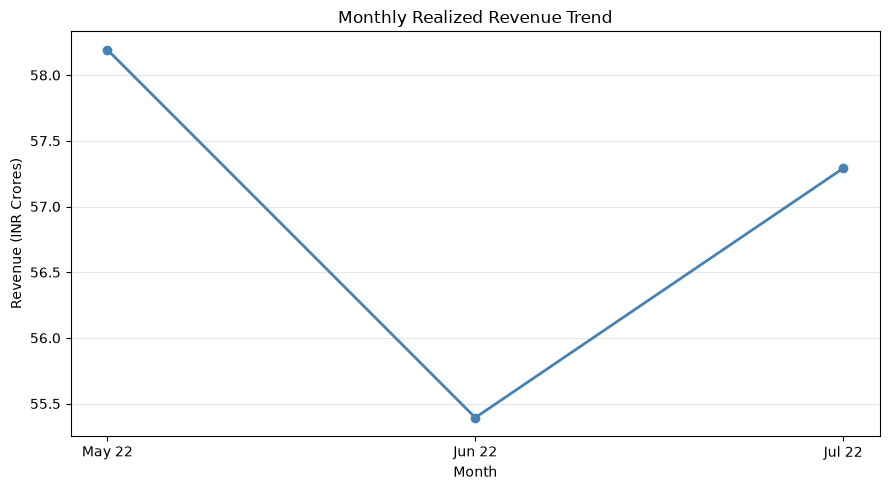

In [59]:
plt.figure(figsize=(9, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values / 10000000, marker="o", color="steelblue", linewidth=2)
plt.title("Monthly Realized Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR Crores)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings

- May recorded the highest realized revenue at ₹58.19 crore.
- Revenue declined by 4.81% in June to ₹55.39 crore.
- July revenue recovered by 3.43% to ₹57.29 crore.
- Despite the recovery, July revenue remained below May levels.

### Business Recommendation
Investigate changes in booking volume and pricing across months; avoid inferring annual seasonality from three months.

## 13. Analyse Realized Revenue by Booking Platform

**Business Objective:** To identify the contribution of each booking
platform to total realized revenue.

In [60]:
revenue_by_platform = df_bookings_all.groupby("booking_platform")["revenue_realized"].sum()

revenue_by_platform

booking_platform
direct offline     86404333
direct online     169026467
journey           102531334
logtrip           187554488
makeyourtrip      340834504
others            699353302
tripster          123066801
Name: revenue_realized, dtype: int64

In [61]:
revenue_contribution = revenue_by_platform / revenue_by_platform.sum() * 100

revenue_contribution.round(2)

booking_platform
direct offline     5.06
direct online      9.89
journey            6.00
logtrip           10.98
makeyourtrip      19.95
others            40.93
tripster           7.20
Name: revenue_realized, dtype: float64

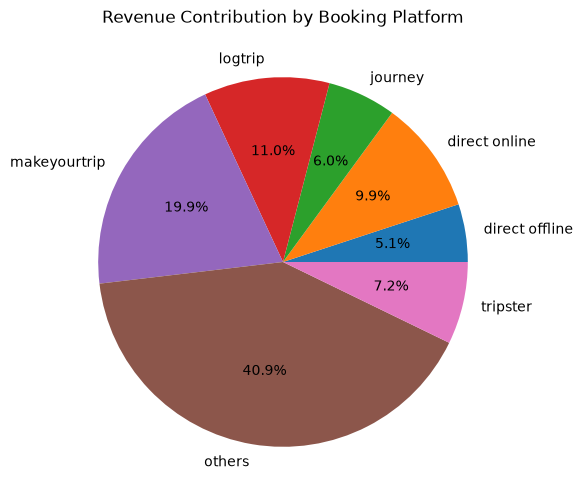

In [62]:
revenue_by_platform.plot(
    kind="pie",
    figsize=(6, 6),
    autopct="%1.1f%%"
)

plt.title("Revenue Contribution by Booking Platform")
plt.ylabel("")
plt.show()

### Key Findings
- Others contributes the largest share of realized revenue (40.93%).
- Direct Offline contributes the smallest share (5.06%).

### Business Recommendation
Compare channel revenue, cancellations and commission costs before changing the channel mix.

## 14. Analyse Cancellation Rate by Booking Platform

In [63]:
total_bookings = df_bookings_all.groupby("booking_platform")["booking_id"].count()

total_bookings

booking_platform
direct offline     6755
direct online     13379
journey            8106
logtrip           14756
makeyourtrip      26898
others            55066
tripster           9630
Name: booking_id, dtype: int64

In [64]:
cancelled_bookings = df_bookings_all[df_bookings_all["booking_status"] == "Cancelled"]
cancelled_bookings = cancelled_bookings.groupby("booking_platform")["booking_id"].count()
cancelled_bookings

booking_platform
direct offline     1654
direct online      3344
journey            2009
logtrip            3586
makeyourtrip       6722
others            13698
tripster           2407
Name: booking_id, dtype: int64

In [65]:
cancellation_rate = (cancelled_bookings / total_bookings) * 100

cancellation_rate = cancellation_rate.fillna(0).round(2)

cancellation_rate.sort_values(ascending=False)

booking_platform
direct online     24.99
tripster          24.99
makeyourtrip      24.99
others            24.88
journey           24.78
direct offline    24.49
logtrip           24.30
Name: booking_id, dtype: float64

In [66]:
cancellation_summary = pd.DataFrame({
    "Total Bookings": total_bookings,
    "Cancelled Bookings": cancelled_bookings,
    "Cancellation Rate (%)": cancellation_rate
})

cancellation_summary = cancellation_summary.fillna(0)

cancellation_summary.sort_values("Cancellation Rate (%)", ascending=False)

,Total Bookings,Cancelled Bookings,Cancellation Rate (%)
booking_platform,,,
direct online,13379,3344,24.99
tripster,9630,2407,24.99
makeyourtrip,26898,6722,24.99
others,55066,13698,24.88
journey,8106,2009,24.78
direct offline,6755,1654,24.49
logtrip,14756,3586,24.30


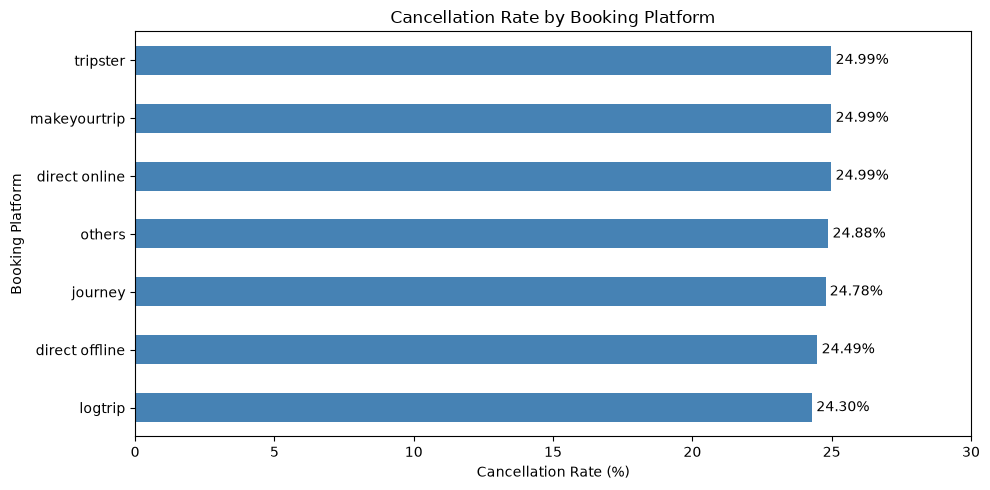

In [67]:
ax = cancellation_rate.sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Booking Platform")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Booking Platform")
plt.xlim(0, 30)
plt.tight_layout()
plt.show()

### Key Findings

- Cancellation rates range from 24.30% to 24.99%.
- The difference between platforms is only 0.69 percentage points.
- Others has the highest cancellation count, but also handles
  a large number of bookings.

### Business Recommendation

Investigate cancellation reasons across all platforms rather
than focusing only on the platform with the highest rate.

## 15. Analyse Potential Unrealized Booking Revenue

**Business Objective:** To identify potential unrealized booking revenue associated with booking cancellations and no-shows, and explore opportunities
to improve revenue realization.

In [68]:
revenue_loss = df_bookings_all[
    df_bookings_all["booking_status"].isin(["Cancelled", "No Show"])
].copy()



In [69]:
revenue_loss["revenue_leakage"] = (
    revenue_loss["revenue_generated"] -
    revenue_loss["revenue_realized"]
)

revenue_loss.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city,month_year,revenue_leakage
1,May012216558RT12,16558,30-04-22,2022-05-01,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22,5460
3,May012216558RT14,16558,28-04-22,2022-05-01,2/5/2022,NaN,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22,5460
6,May012216558RT17,16558,28-04-22,2022-05-01,6/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22,5460
7,May012216558RT18,16558,26-04-22,2022-05-01,3/5/2022,2.0,RT1,logtrip,NaN,No Show,9100,9100,Atliq Grands,Luxury,Delhi,May 22,0
13,May012216558RT114,16558,30-04-22,2022-05-01,5/5/2022,1.0,RT1,logtrip,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,May 22,5460


In [70]:
leakage_by_status = revenue_loss.groupby("booking_status")[
    "revenue_leakage"
].sum()

leakage_by_status

booking_status
Cancelled    300763936
No Show              0
Name: revenue_leakage, dtype: int64

In [71]:
total_revenue_leakage = revenue_loss["revenue_leakage"].sum()

print("Total Revenue Leakage (Cr):",
      round(total_revenue_leakage / 10000000, 2))

Total Revenue Leakage (Cr): 30.08


In [72]:
leakage_by_platform = revenue_loss.groupby("booking_platform")[
    "revenue_leakage"
].sum()

leakage_by_platform.sort_values(ascending=False)

booking_platform
others            123702268
makeyourtrip       60667626
logtrip            31924467
direct online      29743563
tripster           21647709
journey            18123381
direct offline     14954922
Name: revenue_leakage, dtype: int64

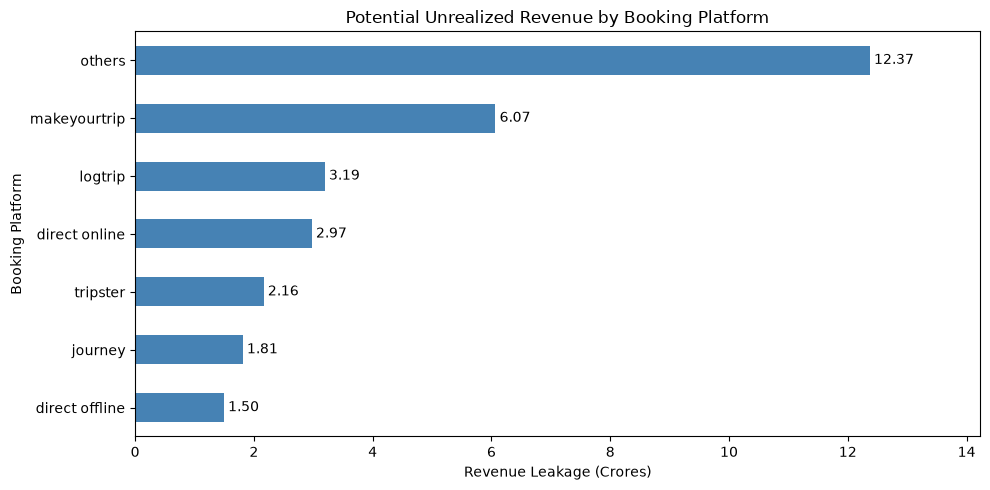

In [73]:
ax = (leakage_by_platform / 10000000).sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.margins(x=0.15)
plt.title("Potential Unrealized Revenue by Booking Platform")
plt.xlabel("Revenue Leakage (Crores)")
plt.ylabel("Booking Platform")
plt.tight_layout()
plt.show()

### Key Findings

- The recorded difference between generated and realized revenue
  for cancellations and no-shows is ₹30.08 crore.
- This estimate includes suspicious generated-revenue values
  that require verification.
- No-shows contribute zero to this recorded difference.
- This figure is not confirmed financial loss or recoverable revenue.

### Business Recommendation

Verify unusual revenue records before using this estimate.
Review cancellation policies and test booking reminders.

## 16. Key Business Insights

### Revenue Performance

- Total realized revenue reached ₹170.88 crore.
- Mumbai was the largest revenue-generating market.
- May recorded the highest monthly revenue at ₹58.19 crore.

### Occupancy Performance

- Weekend occupancy reached 73.58%, compared to
  weekday occupancy of 51.34%.
- The occupancy gap of 22.24 percentage points highlights
  an opportunity to improve weekday demand.
- Presidential rooms recorded the highest occupancy at 59.22%.

### Booking Platform Performance

- The Others booking channel contributed 40.93% of
  total realized revenue.
- Cancellation rates ranged from 24.30% to 24.99%
  across booking platforms.

### Revenue Realization

- Potential unrealized booking revenue amounted to
  ₹30.08 crore, subject to data quality limitations.

## 17. Strategic Business Recommendations
- Test weekday demand initiatives and measure revenue alongside occupancy.
- Compare city capacity and pricing before reallocating resources.
- Evaluate booking channel costs and cancellation behaviour.
- Verify unusual revenue records before using leakage estimates.

## 18. Analysis Limitations
- Occupancy uses total successful bookings divided by total valid capacity, rather than averaging percentages.
- Invalid guest counts are treated as missing; booking revenue is retained.
- Revenue outliers are inspected, not automatically removed.
- August sample records are not included in the May–July analysis.
- Missing customer ratings are not filled with zero.
- Occupancy is based on successful bookings, not confirmed occupied room nights.
- Generated revenue contains unverified extreme values; leakage is not necessarily actual financial loss because rooms may be resold.
- Three months of data cannot establish annual seasonality.

## 19. Conclusion

This project analysed the business performance of AtliQ
Hospitality using Python, Pandas and Matplotlib.

The analysis identified key patterns in hotel occupancy,
revenue distribution, booking platform performance and
customer cancellations.

The findings highlight opportunities to improve weekday
occupancy, evaluate city-level performance and improve
revenue realization.

This project demonstrates how data cleaning, exploratory
data analysis and visualization can transform raw business
data into actionable insights.